<a href="https://colab.research.google.com/github/athfizh/PCVK26_05_Hafizh/blob/main/Modul%207/P7_TugasKelompok_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Laporan Praktikum PCVK - Pertemuan 7**
## **Tugas Kelompok (D2) - Segmentasi Citra dan OCR KTP**

**Kelompok 05 (TI-3F):**
- Arifah Zhafirah Wikananda (`KTP Arifah.jpeg`)
- Joni Yoga Kusuma (`KTP Joni.jpeg`)
- Athaulla Hafizh (NIM 244107020030, Absen 05) (`KTP Hafizh.jpeg`)

---

**Langkah Persiapan: Mount Google Drive, Import Library, dan Lokasi Gambar KTP**

In [10]:
# Mount Google Drive (khusus Google Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

# Library yang digunakan
import os, re, glob, difflib
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Lokasi folder gambar
BASE = '/content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA'

# File KTP untuk setiap anggota
ANGGOTA = {
    'Arifah': 'KTP Arifah.jpeg',
    'Joni'  : 'KTP Joni.jpeg',
    'Hafizh': 'KTP Hafizh.jpeg',
}

def cari_file(nama):
    akar, ext = os.path.splitext(nama)
    kandidat = [nama] + [akar + e for e in ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG', '.PNG')]
    # Cek folder lokal/aktif saat ini
    for k in kandidat:
        if os.path.exists(k):
            return k
    # Cek folder BASE
    for k in kandidat:
        p = os.path.join(BASE, k)
        if os.path.exists(p):
            return p
    # Pencarian rekursif di MyDrive jika di lingkungan Colab
    for p in glob.glob('/content/drive/MyDrive/**/*', recursive=True):
        if os.path.splitext(os.path.basename(p))[0].lower() == akar.lower() \
           and p.lower().endswith(('.jpeg', '.jpg', '.png')):
            return p
    raise FileNotFoundError(f'File "{nama}" tidak ditemukan.')

def muat_citra(nama):
    path = cari_file(nama)
    img = cv.imread(path, cv.IMREAD_COLOR)
    if img is None:
        raise ValueError(f'Gagal membaca citra: {path}')
    print(f'[OK] {nama} -> {path} | ukuran {img.shape}')
    return img

# Verifikasi pembacaan file citra
for nama_anggota, f in ANGGOTA.items():
    muat_citra(f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[OK] KTP Arifah.jpeg -> /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA/KTP Arifah.jpeg | ukuran (1037, 1600, 3)
[OK] KTP Joni.jpeg -> /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA/KTP Joni.jpeg | ukuran (523, 848, 3)
[OK] KTP Hafizh.jpeg -> /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA/KTP Hafizh.jpeg | ukuran (1019, 1573, 3)


---
### **D2. Tugas Kelompok: Konversi Gambar KTP Menjadi Teks (OCR)**
Instalasi Tesseract OCR dan paket bahasa Indonesia (`tesseract-ocr-ind`) untuk ekstraksi teks pada citra KTP.

In [11]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


### **1. Pra-pemrosesan: Pembuatan 3 Varian Citra (Berwarna, Otsu, Adaptive)**
Setiap citra KTP diseragamkan ukurannya (lebar 1200 px). Untuk kedua metode thresholding, citra diubah ke grayscale terlebih dahulu. Citra biner dihasilkan dengan dua metode:
- **Otsu Thresholding**: ambang global optimal dari histogram citra grayscale yang dihaluskan Gaussian $5 \times 5$.
- **Adaptive Gaussian Thresholding**: ambang lokal berbobot Gaussian ($31 \times 31$, $C=10$), diterapkan langsung pada grayscale.

*Catatan:* penghalusan Gaussian hanya dipakai pada jalur Otsu (praktik umum agar histogram lebih stabil); jalur Adaptive memakai grayscale apa adanya. Perbedaan ini perlu diingat saat membandingkan keduanya.


Bahasa OCR : ind | config : --oem 3 --psm 6 | batas confidence : 60
[OK] KTP Arifah.jpeg -> /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA/KTP Arifah.jpeg | ukuran (1037, 1600, 3)
Arifah  | ukuran [(778, 1200), (778, 1200), (778, 1200)] | threshold Otsu = 150
[OK] KTP Joni.jpeg -> /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA/KTP Joni.jpeg | ukuran (523, 848, 3)
Joni    | ukuran [(740, 1200), (740, 1200), (740, 1200)] | threshold Otsu = 138
[OK] KTP Hafizh.jpeg -> /content/drive/MyDrive/COLLEGE/SEM 5/PCVK/BAHAN MODUL/SEGMENTASI CITRA/KTP Hafizh.jpeg | ukuran (1019, 1573, 3)
Hafizh  | ukuran [(777, 1200), (777, 1200), (777, 1200)] | threshold Otsu = 120


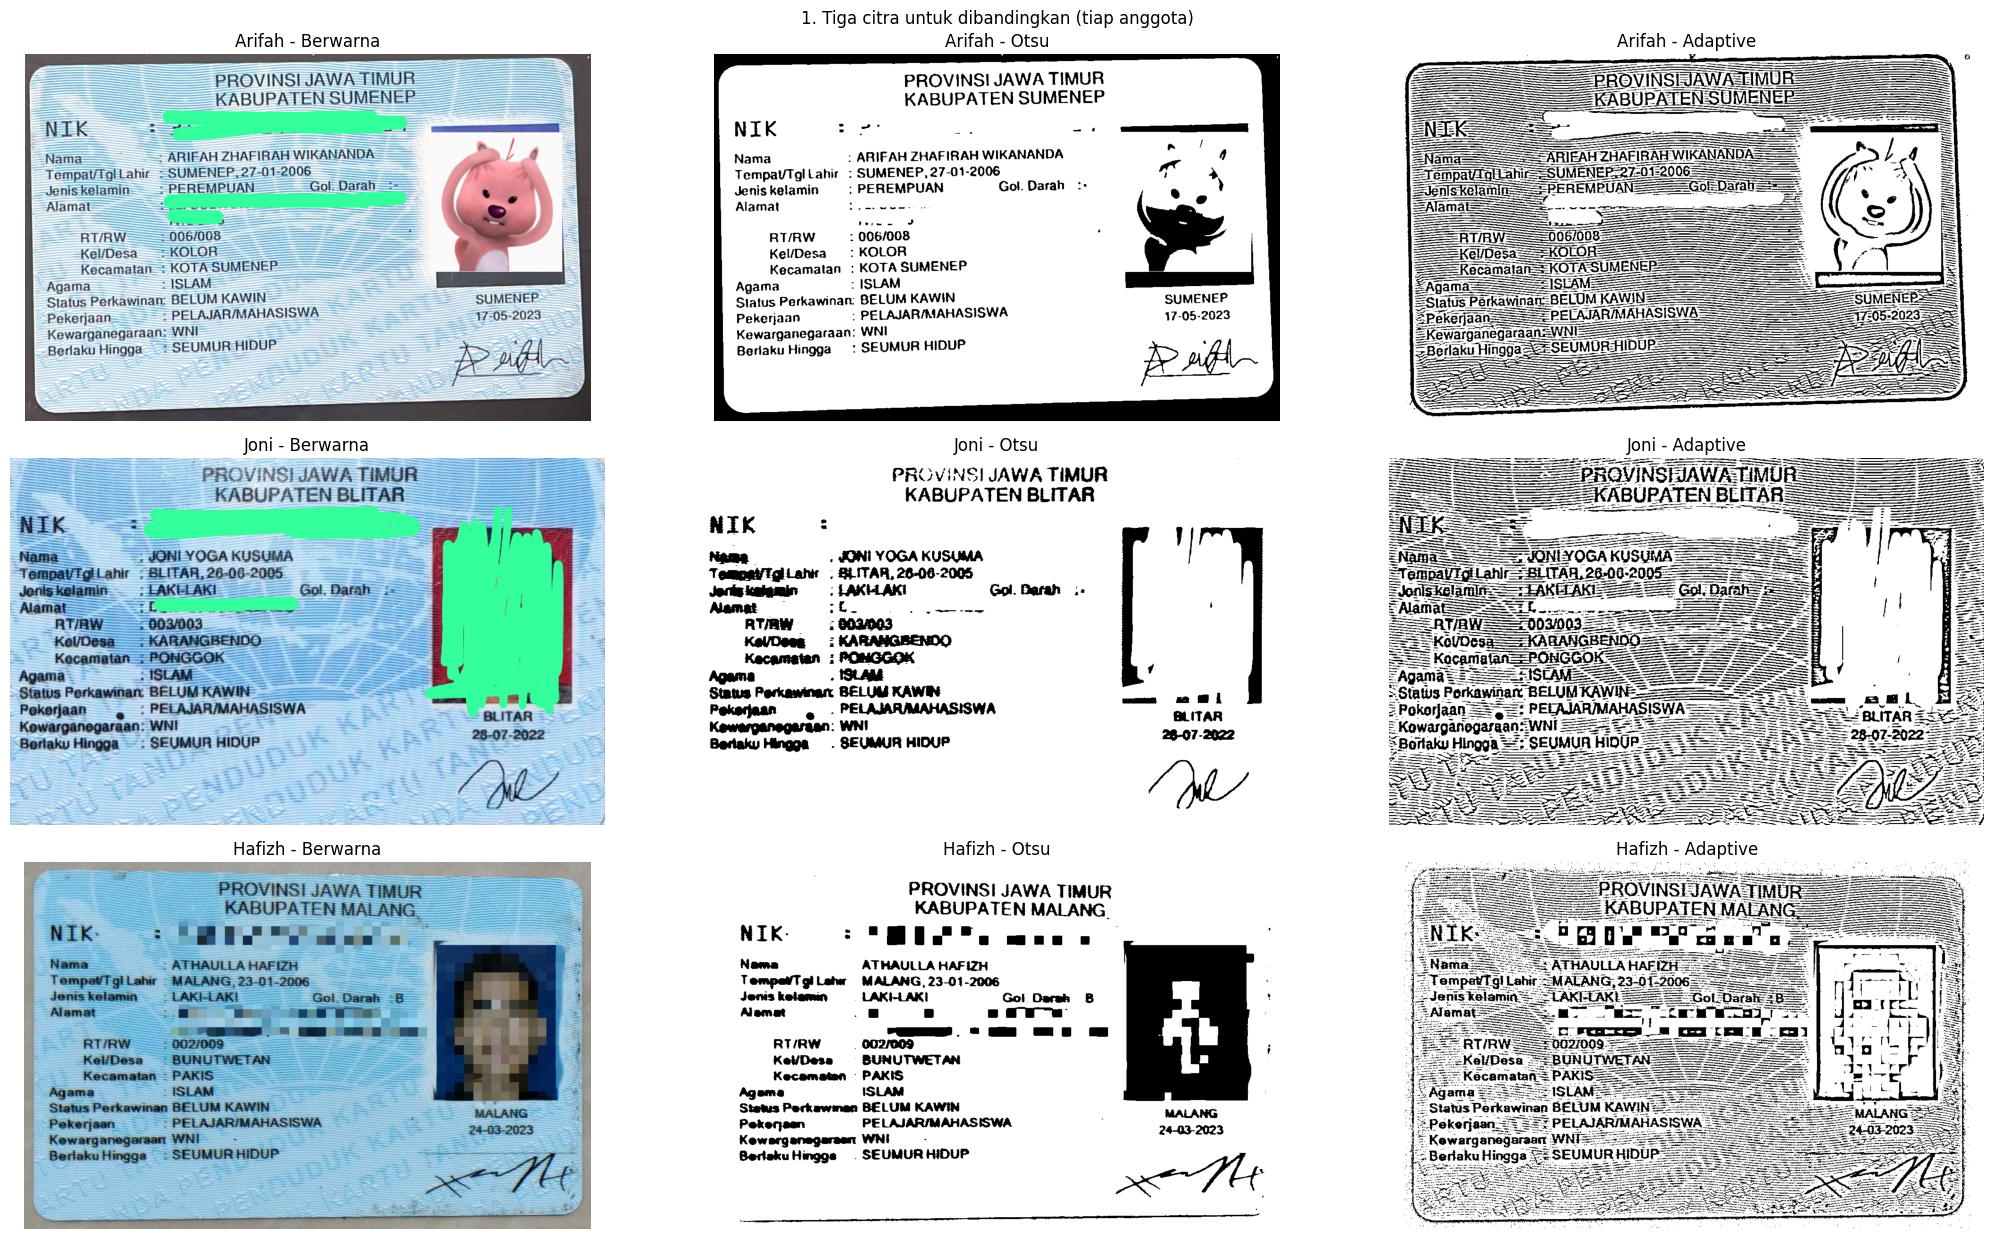

In [12]:
import pytesseract

BAHASA = 'ind' if 'ind' in pytesseract.get_languages(config='') else 'eng'
KONFIG = '--oem 3 --psm 6'     # sama untuk semua citra dan semua anggota
BATAS_CONF = 60                # batas confidence kotak hijau, sama untuk semua citra
LEBAR = 1200                   # lebar seragam ketiga citra

print('Bahasa OCR :', BAHASA, '| config :', KONFIG, '| batas confidence :', BATAS_CONF)
if BAHASA != 'ind':
    print('[!] Model bahasa Indonesia belum terpasang. Jalankan dulu sel instalasi Tesseract di atas.')

def siapkan_tiga_citra(img_bgr):
    # Kembalikan dict {Berwarna, Otsu, Adaptive} dengan ukuran sama + nilai threshold Otsu.
    skala = LEBAR / img_bgr.shape[1]
    besar = cv.resize(img_bgr, None, fx=skala, fy=skala, interpolation=cv.INTER_CUBIC)
    berwarna = cv.cvtColor(besar, cv.COLOR_BGR2RGB)                       # 1. berwarna asli
    gray = cv.cvtColor(besar, cv.COLOR_BGR2GRAY)                          # grayscale dulu
    blur = cv.GaussianBlur(gray, (5, 5), 0)
    t_otsu, otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)   # 2. Otsu
    adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)             # 3. Adaptive
    return {'Berwarna': berwarna, 'Otsu': otsu, 'Adaptive': adaptive}, int(t_otsu)

hasil = {}   # menyimpan semua hasil per anggota
for nama_anggota, f in ANGGOTA.items():
    citra, t_otsu = siapkan_tiga_citra(muat_citra(f))
    hasil[nama_anggota] = {'citra': citra, 't_otsu': t_otsu}
    print(f'{nama_anggota:7s} | ukuran {[c.shape[:2] for c in citra.values()]} | threshold Otsu = {t_otsu}')

plt.figure(figsize=(21, 4.2 * len(hasil)))
k = 1
for nama_anggota, h in hasil.items():
    for metode, c in h['citra'].items():
        plt.subplot(len(hasil), 3, k); k += 1
        plt.imshow(c, cmap='gray' if c.ndim == 2 else None)
        plt.title(f'{nama_anggota} - {metode}'); plt.axis('off')
plt.suptitle('1. Tiga citra untuk dibandingkan (tiap anggota)')
plt.tight_layout(); plt.show()

### **2. Pembacaan Teks Menggunakan `image_to_string()`**
Ekstraksi teks dari seluruh varian citra menggunakan konfigurasi parameter Tesseract `--oem 3 --psm 6` dan bahasa Indonesia.

In [4]:
for nama_anggota, h in hasil.items():
    h['teks'] = {m: pytesseract.image_to_string(c, lang=BAHASA, config=KONFIG)
                 for m, c in h['citra'].items()}
    print('=' * 20, nama_anggota, '- hasil pembacaan citra berwarna', '=' * 20)
    print(h['teks']['Berwarna'].strip(), '\n')

==================== Arifah - hasil pembacaan citra berwarna ====================
5“ PROVINSIJAWA TIMUR” —
ANE ai 5 5
Nama — ARIFAH ZHAFIRAHWIKANANDA-“— TE Re
Tempat/rgkLahir ZSSUMENEP-27-01-2006 — —————— :
Jeniskelamin— — PEREMPUAN Sok Darah — -
na '—'— —
7 3 PARA ||
——— RTIRW 50067008 -
KelDesa SKOLOR PA 5
— —Kecamatan-— KOTASUMENEP
Agama — 5 —— ISLAM PA),
Status Perkawinan: BELUM KAWIN — 55 SUMENEP
Pekerjaan ———-—-: PELAJAR/MAHASISWA -————— 52023
Kewarganegaraan: WNI FS ——- -
Berlaku Hingga “#SEUMUR-HIDUP ——5-———— — , | 

==================== Joni - hasil pembacaan citra berwarna ====================
Pn PROVINSI JAWA HMUR-—— SS
5 KABUPATENBLITAR”—”—””
ama — — — JONLYOGAKUSUMA | 2
Tempat/TgiLats “BLITAR,29-00-2005 —
Ma 5 A—P—55 |
RTAW 0020033

5 Kecamatan BONGGOK-—— —— ---  —— “|

Agama ISLAM 5

Status Perkawinan BELUMKAWIN — ——— 0 mi
Ba 5 BLITAR
Kewargar ega ai 2 - 17 5 2

Berlaku Hingga — : SEUMUR HIDUP. - - 2 25 

==================== Hafizh - hasil pembacaan citra berwarna ======

### **3. Visualisasi Area Teks Terdeteksi (`image_to_data()`)**
Penandaan *bounding box* hijau pada kata-kata yang terdeteksi dengan tingkat *confidence* > 60 pada setiap citra.

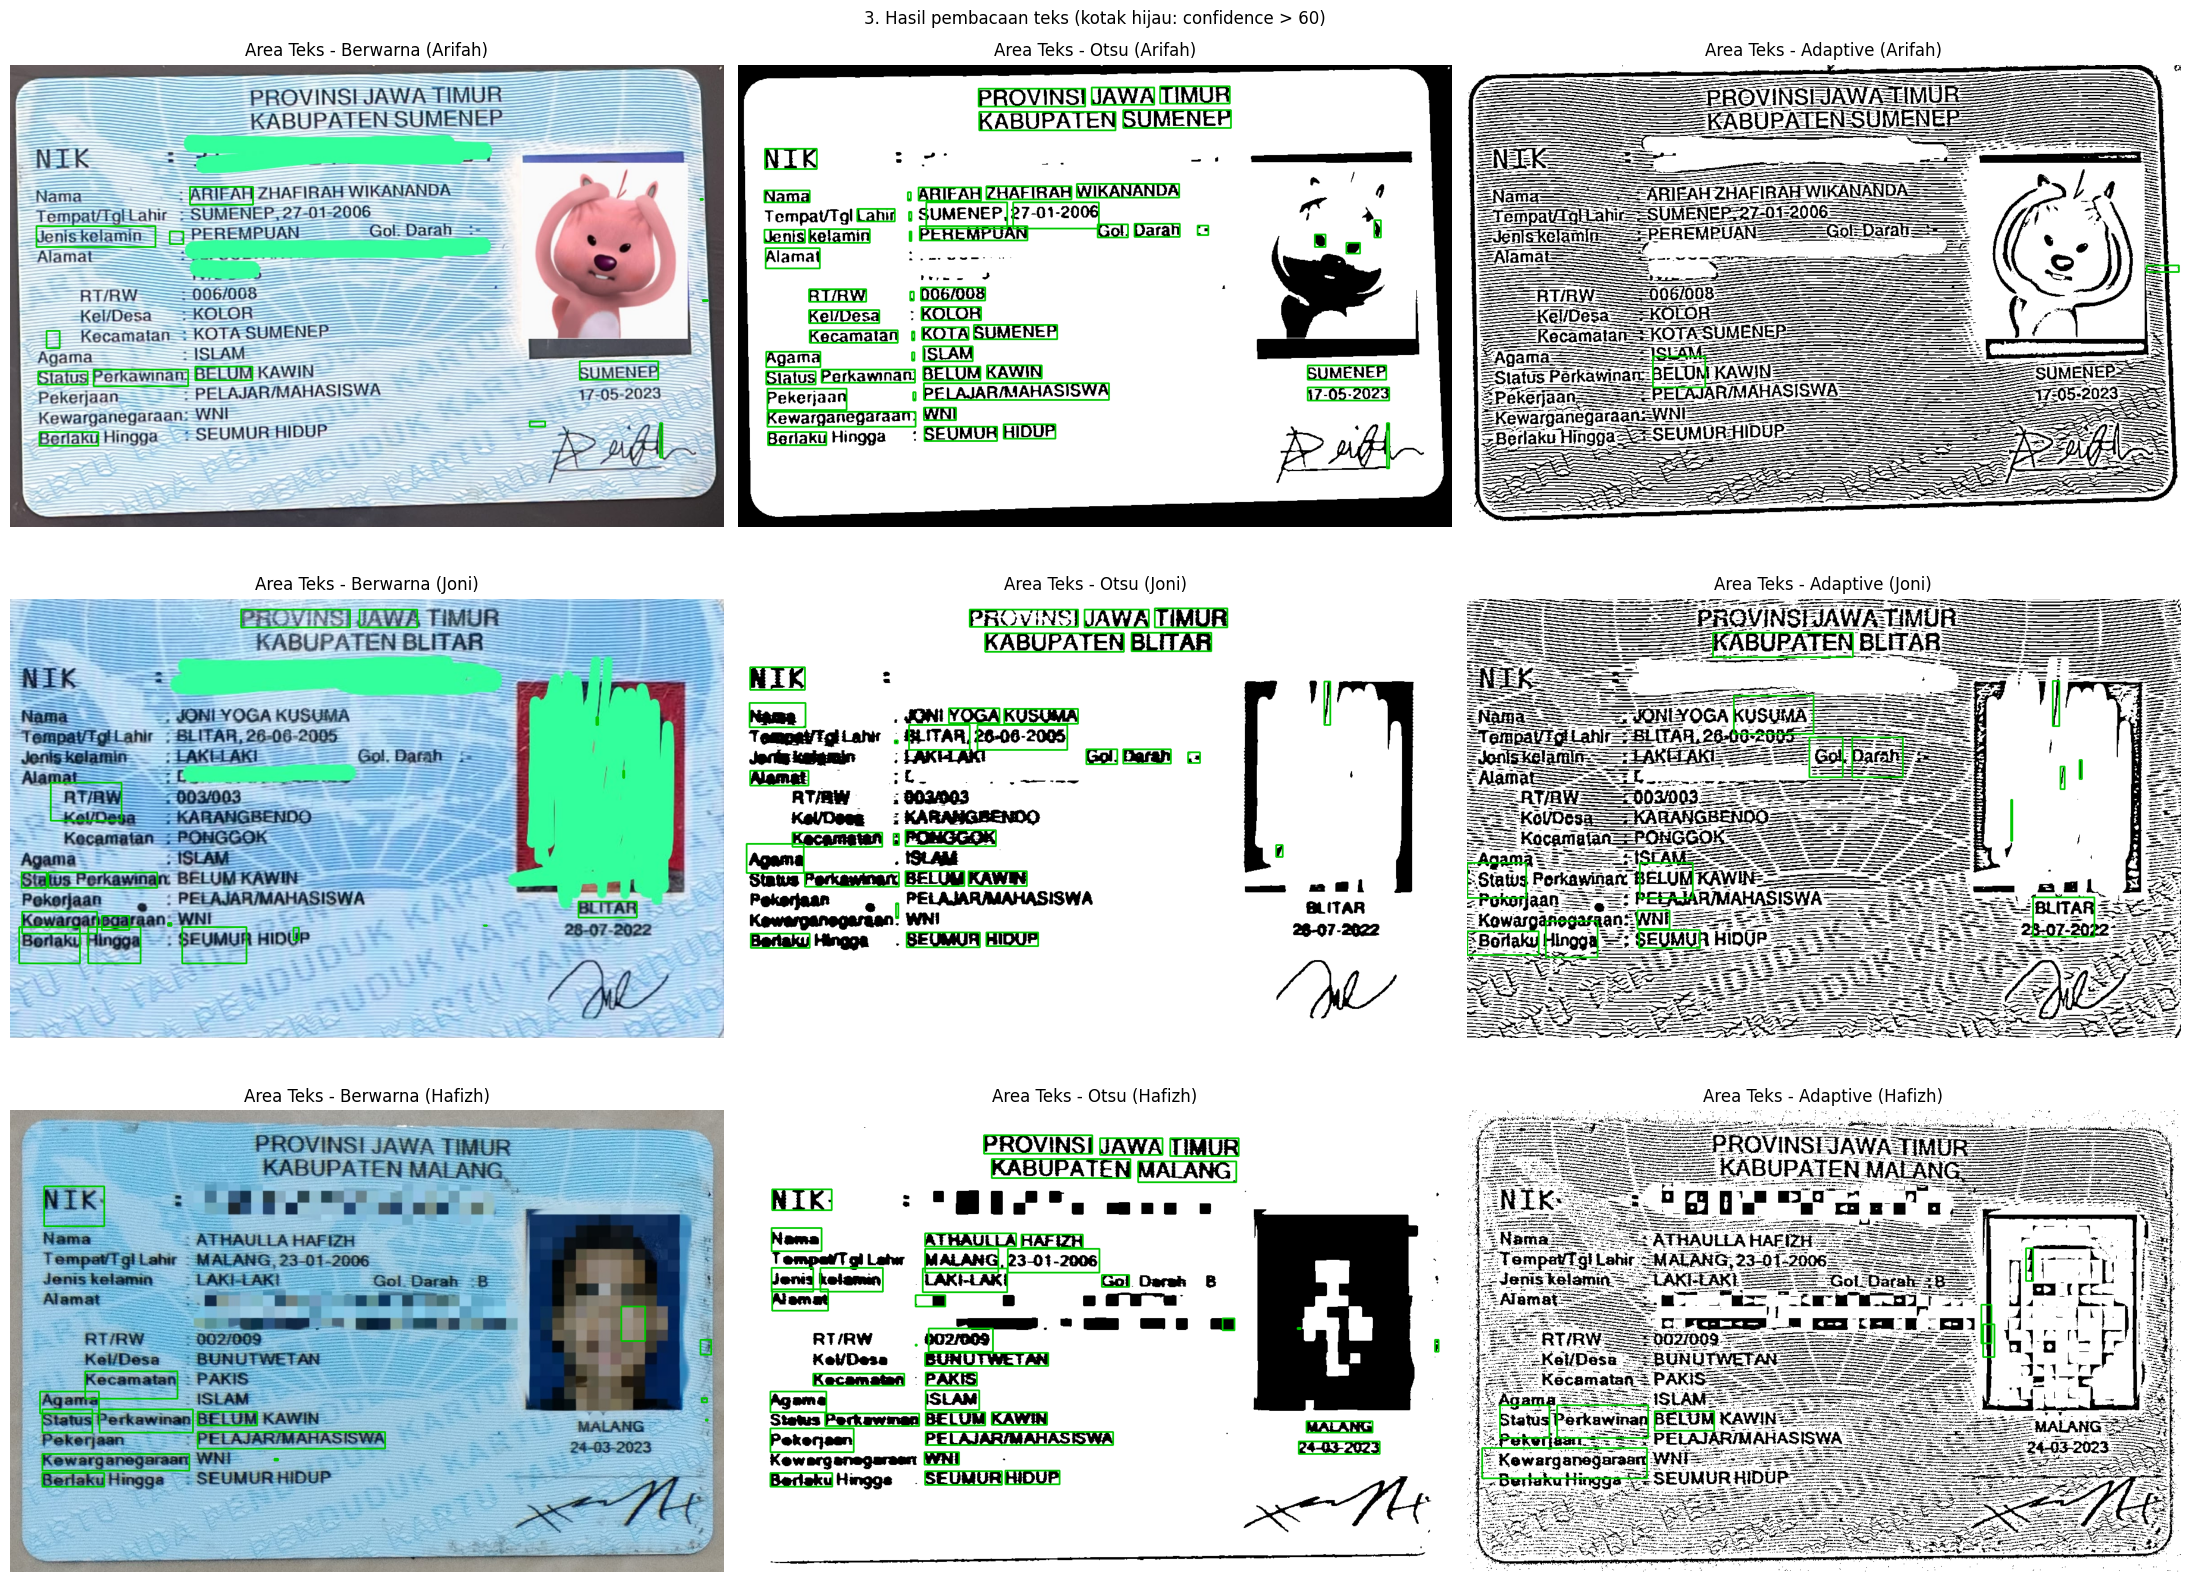

In [5]:
for nama_anggota, h in hasil.items():
    h['data'], h['kotak'] = {}, {}
    for m, c in h['citra'].items():
        d = pytesseract.image_to_data(c, lang=BAHASA, config=KONFIG,
                                      output_type=pytesseract.Output.DICT)
        dasar = c.copy() if c.ndim == 3 else cv.cvtColor(c, cv.COLOR_GRAY2RGB)
        for i in range(len(d['text'])):
            if d['text'][i].strip() and float(d['conf'][i]) > BATAS_CONF:
                x, y, w, hh = d['left'][i], d['top'][i], d['width'][i], d['height'][i]
                cv.rectangle(dasar, (x, y), (x + w, y + hh), (0, 200, 0), 2)
        h['data'][m], h['kotak'][m] = d, dasar

plt.figure(figsize=(22, 5.5 * len(hasil)))
k = 1
for nama_anggota, h in hasil.items():
    for m, c in h['kotak'].items():
        plt.subplot(len(hasil), 3, k); k += 1
        plt.imshow(c); plt.title(f'Area Teks - {m} ({nama_anggota})'); plt.axis('off')
plt.suptitle('3. Hasil pembacaan teks (kotak hijau: confidence > 60)')
plt.tight_layout(); plt.show()

### **4 & 5. Evaluasi Perbandingan Kecocokan Kata Acuan dan Rata-Rata Confidence**
Pengujian dilakukan terhadap 10 kata/angka acuan dari masing-masing KTP anggota. Penilaian kecocokan bersifat *case-insensitive* dan mengabaikan spasi di awal/akhir. Pada fungsi `bersih()` yang dipakai, tanda baca juga diabaikan, sehingga token seperti `SUMENEP.` atau `MALANG,` tetap dihitung tepat. Dampak pelonggaran ini diuji pada sel *uji sensitivitas* di bawah.

$$\text{Kecocokan (\%)} = \frac{\text{Jumlah Item Tepat}}{10} \times 100\%$$

*Rata-rata confidence* dihitung dari semua kata non-kosong yang punya confidence $\geq 0$ (bukan hanya yang $> 60$).


In [6]:
# 10 kata/angka acuan sesuai data KTP masing-masing anggota
ACUAN_ANGGOTA = {
    'Arifah': ['PROVINSI', 'SUMENEP', 'ARIFAH', 'ZHAFIRAH', 'WIKANANDA',
               '27-01-2006', 'PEREMPUAN', 'KOLOR', 'ISLAM', 'SEUMUR'],
    'Joni'  : ['PROVINSI', 'BLITAR', 'JONI', 'YOGA', 'KUSUMA',
               '26-06-2005', 'LAKI-LAKI', 'KARANGBENDO', 'PONGGOK', 'SEUMUR'],
    'Hafizh': ['PROVINSI', 'MALANG', 'ATHAULLA', 'HAFIZH', '23-01-2006',
               'LAKI-LAKI', 'BUNUTWETAN', 'PAKIS', 'ISLAM', 'SEUMUR'],
}

def bersih(s):
    return re.sub(r'[^A-Z0-9]', '', s.upper())

def cek(item, teks_ocr):
    token = teks_ocr.split()
    if not token:
        return '(tidak terbaca)', False
    for t in token:
        if bersih(t) == bersih(item):
            return t.strip(), True
    terdekat = max(token, key=lambda t: difflib.SequenceMatcher(None, bersih(t), bersih(item)).ratio())
    mirip = difflib.SequenceMatcher(None, bersih(terdekat), bersih(item)).ratio()
    return (terdekat.strip() if mirip >= 0.5 else '(tidak terbaca)'), False

def rata_confidence(d):
    c = [float(d['conf'][i]) for i in range(len(d['text']))
         if d['text'][i].strip() and float(d['conf'][i]) >= 0]
    return float(np.mean(c)) if c else 0.0

METODE = ['Berwarna', 'Otsu', 'Adaptive']
NAMA_TAMPIL = {'Berwarna': 'Berwarna asli', 'Otsu': 'Segmentasi Otsu', 'Adaptive': 'Segmentasi Adaptive'}

for nama_anggota, h in hasil.items():
    acuan = ACUAN_ANGGOTA[nama_anggota]
    baris, benar, salah = [], {m: 0 for m in METODE}, []
    for no, item in enumerate(acuan, 1):
        isi = [no, item]
        for m in METODE:
            kata, ok = cek(item, h['teks'][m])
            benar[m] += int(ok)
            if not ok:
                salah.append((m, item, kata))
            isi.append(kata if ok else f'{kata} (x)')
        baris.append(isi)
    h['tabel'] = pd.DataFrame(baris, columns=['No.', 'Teks sebenarnya', 'OCR citra berwarna', 'OCR Otsu', 'OCR Adaptive'])
    h['salah'] = salah
    h['ringkasan'] = pd.DataFrame({
        'Citra masukan OCR'   : [NAMA_TAMPIL[m] for m in METODE],
        'Item terbaca tepat'  : [benar[m] for m in METODE],
        'Kecocokan (%)'       : [100 * benar[m] / len(acuan) for m in METODE],
        'Rata-rata confidence': [round(rata_confidence(h['data'][m]), 2) for m in METODE],
    })
    print(f"{'='*25} {nama_anggota} {'='*25}")
    print(h['tabel'].to_string(index=False), '\n')
    print(h['ringkasan'].to_string(index=False), '\n')

========================= Arifah =========================
 No. Teks sebenarnya       OCR citra berwarna   OCR Otsu               OCR Adaptive
   1        PROVINSI         PROVINSIJAWA (x)   PROVINSI         ROVNSIJAWANMUR (x)
   2         SUMENEP                  SUMENEP    SUMENEP                   SUMENEP.
   3          ARIFAH                   ARIFAH     ARIFAH                   Dafa (x)
   4        ZHAFIRAH ZHAFIRAHWIKANANDA-“— (x)   ZHAFIRAH                   Dafa (x)
   5       WIKANANDA ZHAFIRAHWIKANANDA-“— (x)  WIKANANDA ARIPAM2HAPRAHWIKANANDA (x)
   6      27-01-2006 ZSSUMENEP-27-01-2006 (x) 27-01-2006        (tidak terbaca) (x)
   7       PEREMPUAN                PEREMPUAN  PEREMPUAN                  PEREMPUAN
   8           KOLOR               SKOLOR (x)      KOLOR                      KOLOR
   9           ISLAM                    ISLAM      ISLAM                    ame (x)
  10          SEUMUR       “#SEUMUR-HIDUP (x)     SEUMUR                     SEUMUR 

  Citra masukan

### **Ringkasan Evaluasi Kelompok**
Rekapitulasi perbandingan performa OCR dari ketiga KTP anggota beserta nilai rata-rata kelompok untuk setiap metode binarisasi.

In [7]:
baris_g = []
for nama_anggota, h in hasil.items():
    for m in METODE:
        r = h['ringkasan'][h['ringkasan']['Citra masukan OCR'] == NAMA_TAMPIL[m]].iloc[0]
        baris_g.append([nama_anggota, NAMA_TAMPIL[m], int(r['Item terbaca tepat']),
                        r['Kecocokan (%)'], r['Rata-rata confidence']])

rinci = pd.DataFrame(baris_g, columns=['Anggota', 'Citra masukan OCR', 'Item terbaca tepat',
                                       'Kecocokan (%)', 'Rata-rata confidence'])
print('Rincian per Anggota:')
print(rinci.to_string(index=False), '\n')

gabungan = (rinci.groupby('Citra masukan OCR', sort=False)
                 .agg(**{'Rata-rata item tepat': ('Item terbaca tepat', 'mean'),
                         'Rata-rata kecocokan (%)': ('Kecocokan (%)', 'mean'),
                         'Rata-rata confidence': ('Rata-rata confidence', 'mean')}).round(2))
print('Rata-rata Gabungan Kelompok:')
print(gabungan.to_string())

Rincian per Anggota:
Anggota   Citra masukan OCR  Item terbaca tepat  Kecocokan (%)  Rata-rata confidence
 Arifah       Berwarna asli                   4           40.0                 33.55
 Arifah     Segmentasi Otsu                  10          100.0                 74.46
 Arifah Segmentasi Adaptive                   4           40.0                 17.93
   Joni       Berwarna asli                   3           30.0                 38.49
   Joni     Segmentasi Otsu                   6           60.0                 62.55
   Joni Segmentasi Adaptive                   2           20.0                 25.49
 Hafizh       Berwarna asli                   4           40.0                 33.38
 Hafizh     Segmentasi Otsu                  10          100.0                 59.83
 Hafizh Segmentasi Adaptive                   2           20.0                 26.24 

Rata-rata Gabungan Kelompok:
                     Rata-rata item tepat  Rata-rata kecocokan (%)  Rata-rata confidence
Citra mas

### **Uji Sensitivitas Kriteria Penilaian**
Sel berikut menghitung ulang kecocokan dengan kriteria yang lebih ketat (tanda baca tidak diabaikan) untuk memastikan kesimpulan tidak bergantung pada pelonggaran `bersih()`.


In [8]:
# Uji sensitivitas: penilaian ketat (hanya abaikan huruf besar/kecil dan spasi awal/akhir)
# Tanda baca TIDAK diabaikan, sesuai kriteria soal.
def cek_ketat(item, teks_ocr):
    return any(t.strip().upper() == item.upper() for t in teks_ocr.split())

baris_k = []
for nama_anggota, h in hasil.items():
    acuan = ACUAN_ANGGOTA[nama_anggota]
    for m in METODE:
        tepat = sum(cek_ketat(item, h['teks'][m]) for item in acuan)
        baris_k.append([nama_anggota, NAMA_TAMPIL[m], tepat, 100 * tepat / len(acuan)])

ketat = pd.DataFrame(baris_k, columns=['Anggota', 'Citra masukan OCR', 'Item tepat (ketat)', 'Kecocokan ketat (%)'])
print(ketat.to_string(index=False), '\n')
print('Rata-rata kelompok (penilaian ketat):')
print(ketat.groupby('Citra masukan OCR', sort=False)['Kecocokan ketat (%)'].mean().round(2).to_string())


Anggota   Citra masukan OCR  Item tepat (ketat)  Kecocokan ketat (%)
 Arifah       Berwarna asli                   4                 40.0
 Arifah     Segmentasi Otsu                  10                100.0
 Arifah Segmentasi Adaptive                   3                 30.0
   Joni       Berwarna asli                   3                 30.0
   Joni     Segmentasi Otsu                   6                 60.0
   Joni Segmentasi Adaptive                   2                 20.0
 Hafizh       Berwarna asli                   3                 30.0
 Hafizh     Segmentasi Otsu                  10                100.0
 Hafizh Segmentasi Adaptive                   2                 20.0 

Rata-rata kelompok (penilaian ketat):
Citra masukan OCR
Berwarna asli          33.33
Segmentasi Otsu        86.67
Segmentasi Adaptive    23.33


---
# **Analisis dan Pembahasan**

In [9]:
print('Ringkasan Hasil Evaluasi:')
for nama_anggota, h in hasil.items():
    r = h['ringkasan']
    tertinggi = r['Kecocokan (%)'].max()
    unggul = r.loc[r['Kecocokan (%)'] == tertinggi, 'Citra masukan OCR'].tolist()
    print(f" - {nama_anggota:7s} -> Akurasi tertinggi {tertinggi:.0f}% pada {', '.join(unggul)}")

print(f"\nMetode terbaik secara keseluruhan: {gabungan['Rata-rata kecocokan (%)'].idxmax()}"
      f" (rata-rata {gabungan['Rata-rata kecocokan (%)'].max():.1f}%)")

Ringkasan Hasil Evaluasi:
 - Arifah  -> Akurasi tertinggi 100% pada Segmentasi Otsu
 - Joni    -> Akurasi tertinggi 60% pada Segmentasi Otsu
 - Hafizh  -> Akurasi tertinggi 100% pada Segmentasi Otsu

Metode terbaik secara keseluruhan: Segmentasi Otsu (rata-rata 86.7%)


### **Jawaban Pertanyaan Analisis**

**1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.**

Citra hasil segmentasi **Otsu** menghasilkan pembacaan paling tepat. Buktinya:

| Citra masukan OCR | Arifah | Joni | Hafizh | Rata-rata kecocokan | Rata-rata confidence |
|---|---|---|---|---|---|
| Berwarna asli | 40% | 30% | 40% | 36,67% | 35,14 |
| Segmentasi Otsu | **100%** | **60%** | **100%** | **86,67%** | **65,61** |
| Segmentasi Adaptive | 40% | 20% | 20% | 26,67% | 23,22 |

Otsu unggul pada ketiga KTP. Pada KTP Arifah dan Hafizh, kesepuluh kata acuan terbaca tepat. Kecocokan Otsu terendah ada pada KTP Joni (60%), yang resolusi aslinya paling kecil (848 × 523 px, diperbesar ke lebar 1200 px sehingga hurufnya agak kabur). Meski begitu, angka itu masih dua kali lipat citra berwarna (30%) dan tiga kali lipat Adaptive (20%) pada KTP yang sama. Citra **berwarna asli tidak termasuk yang terbaik**: rata-ratanya hanya 36,67%, jauh di bawah Otsu.

Uji sensitivitas dengan penilaian ketat (tanda baca tidak diabaikan) tidak mengubah urutan ini: rata-rata kecocokan menjadi 33,33% (berwarna), 86,67% (Otsu), dan 23,33% (Adaptive).

**2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.**

Kesalahan berikut diambil dari tabel hasil OCR:
1. *Huruf/angka salah baca:* pada Joni (Otsu), tanggal lahir `26-06-2005` terbaca `20-00-2005` dan `LAKI-LAKI` terbaca `HAKELAKI`. Pada Joni (berwarna), `PONGGOK` terbaca `BONGGOK`. Pada Hafizh (berwarna), `ISLAM` terbaca `SAM`.
2. *Kata menyatu dan karakter sisipan:* pada Arifah (berwarna), `ZHAFIRAH WIKANANDA` terbaca `ZHAFIRAHWIKANANDA-“—`, dan `KOLOR` terbaca `SKOLOR`. Spasi antarkata hilang dan muncul karakter tambahan dari garis atau latar.
3. *Teks tidak terbaca atau salah total:* pada Hafizh (berwarna), 5 dari 10 item berstatus `(tidak terbaca)` (misalnya `ATHAULLA`, `HAFIZH`, `LAKI-LAKI`). Pada Adaptive, `ARIFAH` terbaca `Dafa` dan `ISLAM` terbaca `ame`.

**3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.**

**Tidak selalu.** Segmentasi Otsu meningkatkan rata-rata kecocokan dari 36,67% (berwarna) menjadi 86,67%, tetapi segmentasi Adaptive justru menurunkannya menjadi 26,67%. Jadi pengaruh segmentasi bergantung pada metode dan parameternya.

Dari Gambar 1, hasil Otsu memperlihatkan teks hitam pekat di atas latar putih bersih, dengan pola latar KTP hampir hilang. Hasil Adaptive masih menyisakan pola garis latar sebagai tekstur hitam-putih padat di seluruh kartu, dan huruf kecil bercampur dengan tekstur itu. Dugaan kami, jendela lokal $31 \times 31$ dengan $C = 10$ yang diterapkan tanpa penghalusan membuat variasi halus pada latar ikut ditandai sebagai objek. Ini penjelasan atas pengamatan visual, bukan hasil pengujian parameter lain.

**4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?**

KTP berlatar biru muda dengan pola garis dan tulisan pengaman. Pada citra berwarna, pola ini berdekatan tingkat terangnya dengan teks kecil, sehingga Tesseract sering gagal. Contohnya KTP Hafizh yang separuh itemnya `(tidak terbaca)`, dan hasil Arifah yang bercampur karakter sisipan seperti `SKOLOR`. Otsu menghasilkan ambang global yang memisahkan teks gelap dari latar yang lebih terang, sehingga pola latar hampir hilang (Gambar 1) dan pembacaan membaik. Pada Adaptive, pola latar tetap terlihat sebagai noise, dan kata sering terbaca salah (`Dafa`, `ame`) atau tidak terbaca. Kualitas foto juga kemungkinan berpengaruh: KTP Joni, yang resolusinya paling kecil, mendapat skor terendah pada citra berwarna dan Otsu, dan sama rendahnya dengan Hafizh pada Adaptive (20%). Pengaruh resolusi ini tidak diuji terpisah.

**5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?**

**Pada percobaan ini ya**: Otsu punya confidence tertinggi (65,61) sekaligus kecocokan tertinggi (86,67%), dan hal yang sama berlaku pada ketiga KTP secara terpisah. Namun keduanya tidak selalu sejalan, seperti terlihat dari data yang sama:
- Pada Arifah, citra berwarna dan Adaptive sama-sama 40%, tetapi confidence-nya 33,55 vs 17,93.
- Otsu pada Arifah dan Hafizh sama-sama 100%, tetapi confidence-nya 74,46 vs 59,83.
- Otsu pada Joni punya confidence (62,55) lebih tinggi daripada Hafizh (59,83), padahal kecocokannya jauh lebih rendah (60% vs 100%).

Confidence mengukur keyakinan model terhadap bentuk karakter, bukan kebenaran terhadap teks acuan, sehingga tetap perlu dibandingkan langsung dengan acuan.


---
# **Kesimpulan**

1. **Performa metode:** Pada KTP ketiga anggota, segmentasi **Otsu** memberi pembacaan terbaik (rata-rata kecocokan 86,67%, confidence 65,61). Citra **berwarna asli** berada di tengah (36,67%; 35,14) dan **Adaptive Gaussian Thresholding** terendah (26,67%; 23,22).
2. **Efektivitas segmentasi:** Segmentasi tidak selalu meningkatkan OCR. Otsu membersihkan pola latar biru KTP sehingga teks terbaca jelas, sedangkan Adaptive (jendela $31 \times 31$, $C=10$) menyisakan tekstur latar yang diduga mengganggu pembacaan.
3. **Faktor lain:** Kualitas foto kemungkinan ikut memengaruhi hasil. KTP Joni (resolusi terkecil) mendapat skor terendah pada citra berwarna dan Otsu (60%), dan sama rendahnya dengan Hafizh pada Adaptive (20%). Pengaruh resolusi tidak diuji terpisah.
4. **Confidence vs kecocokan:** Pada percobaan ini Otsu unggul di kedua metrik, tetapi data per anggota menunjukkan confidence tidak selalu sebanding dengan kecocokan. Verifikasi OCR tetap memerlukan perbandingan dengan teks acuan.
5. **Keterbatasan:** Sampel hanya 3 KTP dengan 10 item acuan per KTP, dan parameter Adaptive tidak divariasikan. Pencocokan kata acuan dilakukan terhadap seluruh teks hasil OCR, bukan pada baris isian tertentu, sehingga kata seperti nama kota dapat terhitung benar dari baris "KABUPATEN ..." meskipun baris tempat lahirnya salah baca. Uji sensitivitas dengan penilaian ketat (Berwarna 33,33%; Otsu 86,67%; Adaptive 23,33%) tidak mengubah urutan metode. Hasil bersifat indikatif, bukan generalisasi.
